In [ ]:
# UNSUPERVISED LEARNING

In [ ]:
#DATASET UNDERSTANDING

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.decomposition import PCA

%matplotlib inline
sns.set(style="whitegrid")

In [4]:
df = pd.read_csv('online_shoppers_intention.csv')
print("Step 1.2: Raw data loaded into memory.")

Step 1.2: Raw data loaded into memory.


In [5]:
display(df.head())
display(df.tail())

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
12325,3,145.0,0,0.0,53,1783.791667,0.007143,0.029031,12.241717,0.0,Dec,4,6,1,1,Returning_Visitor,True,False
12326,0,0.0,0,0.0,5,465.750000,0.000000,0.021333,0.000000,0.0,Nov,3,2,1,8,Returning_Visitor,True,False
12327,0,0.0,0,0.0,6,184.250000,0.083333,0.086667,0.000000,0.0,Nov,3,2,1,13,Returning_Visitor,True,False
12328,4,75.0,0,0.0,15,346.000000,0.000000,0.021053,0.000000,0.0,Nov,2,2,3,11,Returning_Visitor,False,False
12329,0,0.0,0,0.0,3,21.250000,0.000000,0.066667,0.000000,0.0,Nov,3,2,1,2,New_Visitor,True,False


In [6]:
print(f"Dataset Shape: {df.shape}")
df.info()

Dataset Shape: (12330, 18)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  


In [7]:
df.describe(include='all')

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
count,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330,12330.000000,12330.000000,12330.000000,12330.000000,12330,12330,12330
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10,NaN,NaN,NaN,NaN,3,2,2
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,May,NaN,NaN,NaN,NaN,Returning_Visitor,False,False
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3364,NaN,NaN,NaN,NaN,10551,9462,10422
mean,2.315166,80.818611,0.503569,34.472398,31.731468,1194.746220,0.022191,0.043073,5.889258,0.061427,NaN,2.124006,2.357097,3.147364,4.069586,NaN,NaN,NaN
std,3.321784,176.779107,1.270156,140.749294,44.475503,1913.669288,0.048488,0.048597,18.568437,0.198917,NaN,0.911325,1.717277,2.401591,4.025169,NaN,NaN,NaN
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,1.000000,1.000000,1.000000,1.000000,NaN,NaN,NaN
25%,0.000000,0.000000,0.000000,0.000000,7.000000,184.137500,0.000000,0.014286,0.000000,0.000000,NaN,2.000000,2.000000,1.000000,2.000000,NaN,NaN,NaN
50%,1.000000,7.500000,0.000000,0.000000,18.000000,598.936905,0.003112,0.025156,0.000000,0.000000,NaN,2.000000,2.000000,3.000000,2.000000,NaN,NaN,NaN
75%,4.000000,93.256250,0.000000,0.000000,38.000000,1464.157214,0.016813,0.050000,0.000000,0.000000,NaN,3.000000,2.000000,4.000000,4.000000,NaN,NaN,NaN


In [8]:
df.shape

(12330, 18)

In [9]:
df_original = pd.read_csv('online_shoppers_intention.csv')
print('Total rows:', len(df_original))
print('Duplicate rows:', df_original.duplicated().sum())

Total rows: 12330
Duplicate rows: 125


In [10]:
#Data Types and Column Inventory
print("Column Names:", df.columns.tolist())
print("\nData Types:\n", df.dtypes)

Column Names: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend', 'Revenue']

Data Types:
 Administrative               int64
Administrative_Duration    float64
Informational                int64
Informational_Duration     float64
ProductRelated               int64
ProductRelated_Duration    float64
BounceRates                float64
ExitRates                  float64
PageValues                 float64
SpecialDay                 float64
Month                       object
OperatingSystems             int64
Browser                      int64
Region                       int64
TrafficType                  int64
VisitorType                 object
Weekend                       bool
Revenue                       bool
dtype: object


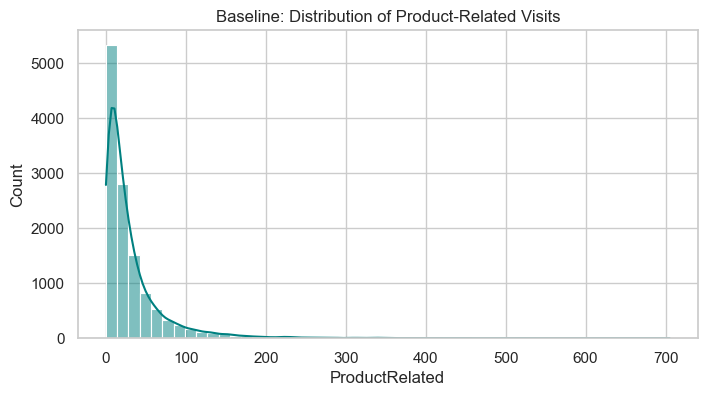

In [11]:
#INITIAL EDA (Baseline Visualization)
plt.figure(figsize=(8, 4))
sns.histplot(df['ProductRelated'], bins=50, color='teal', kde=True)
plt.title('Baseline: Distribution of Product-Related Visits')
plt.show()

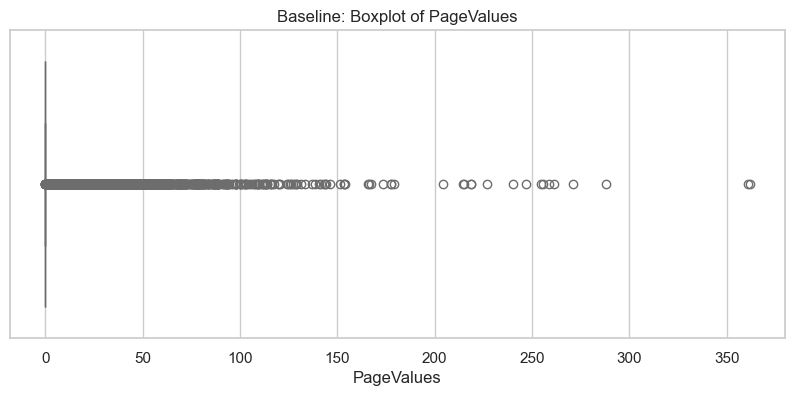

In [12]:
plt.figure(figsize=(10, 4))
sns.boxplot(x=df['PageValues'], color='salmon')
plt.title('Baseline: Boxplot of PageValues')
plt.show()

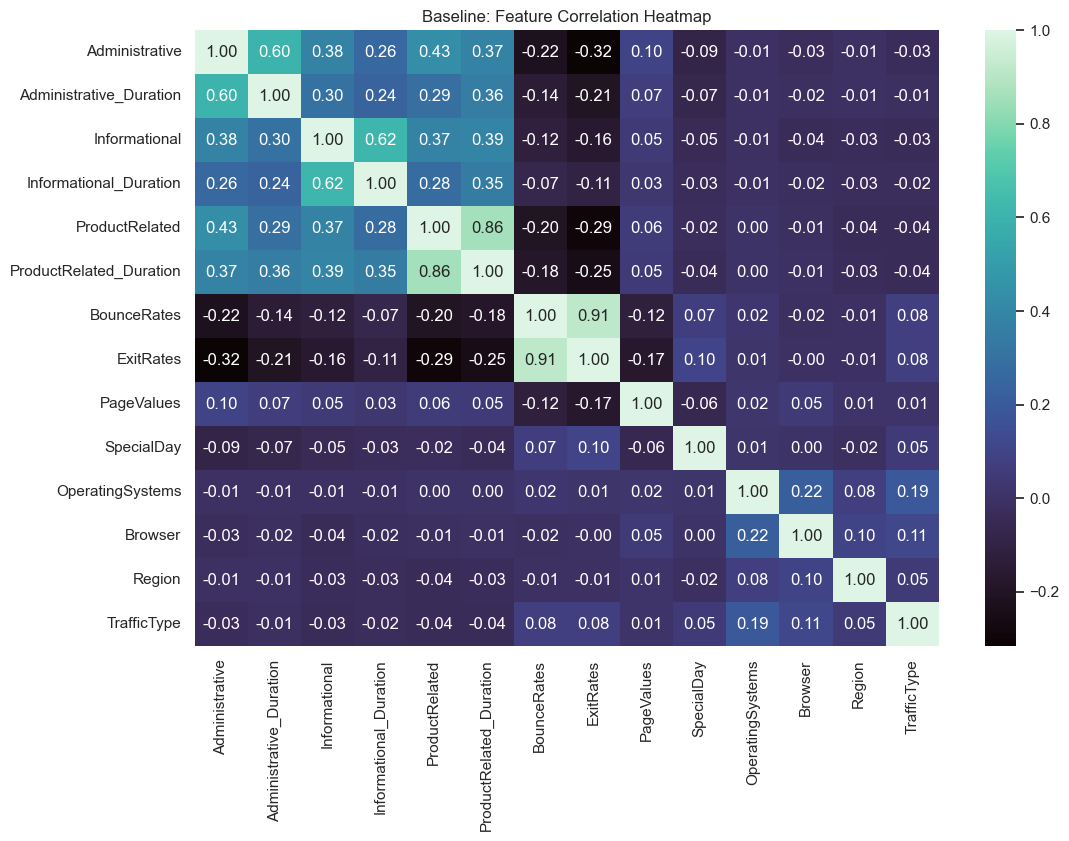

In [13]:
plt.figure(figsize=(12, 8))
sns.heatmap(df.select_dtypes(include=[np.number]).corr(), annot=True, cmap='mako', fmt='.2f')
plt.title('Baseline: Feature Correlation Heatmap')
plt.show()

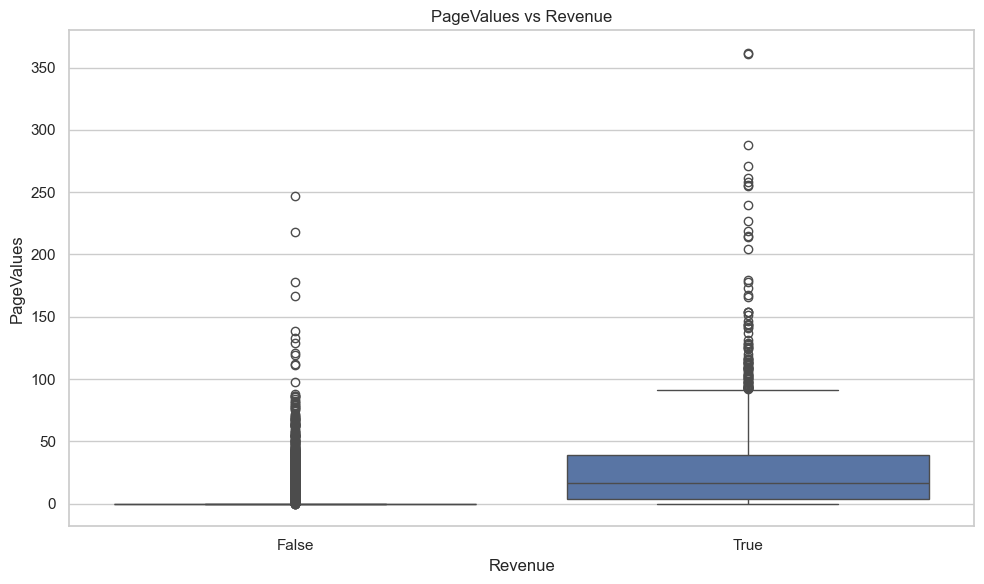

In [14]:
#relation
plt.figure(figsize=(10,6))

sns.boxplot(
    x='Revenue',
    y='PageValues',
    data=df
)

plt.title('PageValues vs Revenue')
plt.tight_layout()
plt.show()

In [15]:
#PHASE 3 — MISSING VALUE ANALYSIS
print("Null Value Count per Column:")
print(df.isnull().sum())

Null Value Count per Column:
Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64


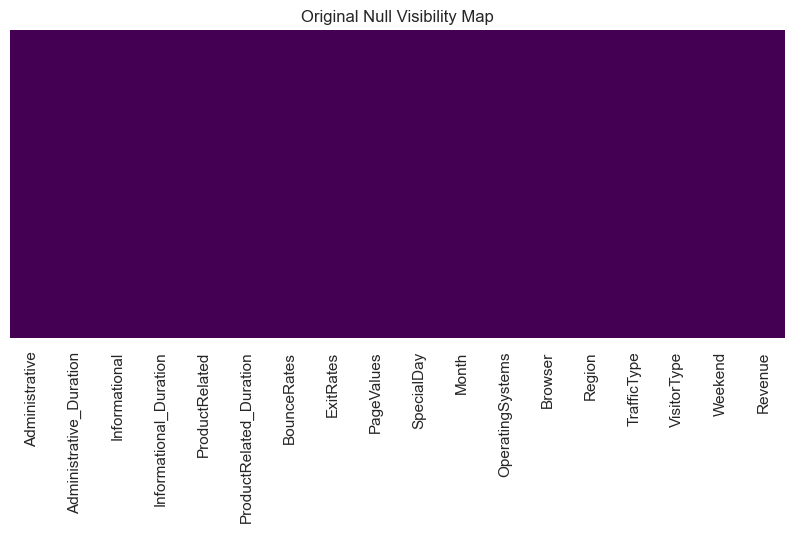

In [16]:
plt.figure(figsize=(10, 4))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap='viridis')
plt.title('Original Null Visibility Map')
plt.show()

Successfully corrupted 500 rows in 'Administrative_Duration'.


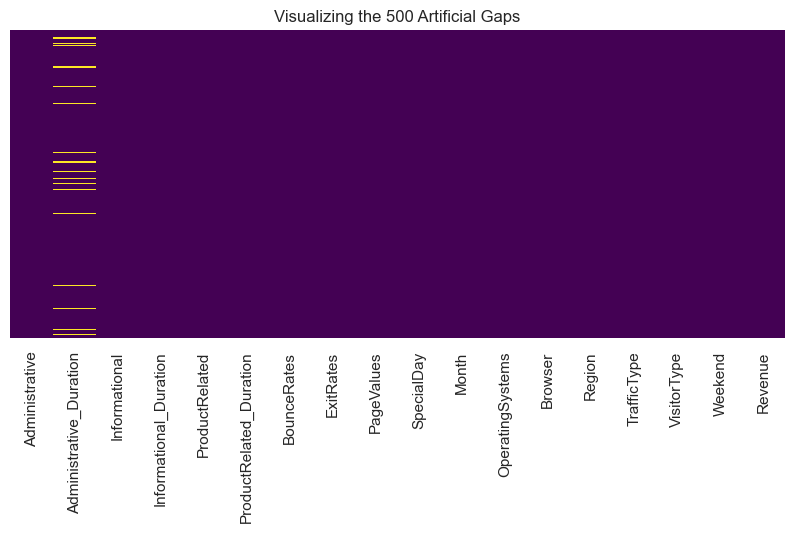

In [17]:
# add missing values
df_broken = df.copy()
np.random.seed(42)
indices = np.random.choice(df_broken.index, 500, replace=False)
df_broken.loc[indices, 'Administrative_Duration'] = np.nan

print(f"Successfully corrupted 500 rows in 'Administrative_Duration'.")

plt.figure(figsize=(10, 4))
sns.heatmap(df_broken.isnull(), cbar=False, yticklabels=False, cmap='viridis')
plt.title('Visualizing the 500 Artificial Gaps')
plt.show()

In [18]:
print(df_broken.isnull().sum())

Administrative               0
Administrative_Duration    500
Informational                0
Informational_Duration       0
ProductRelated               0
ProductRelated_Duration      0
BounceRates                  0
ExitRates                    0
PageValues                   0
SpecialDay                   0
Month                        0
OperatingSystems             0
Browser                      0
Region                       0
TrafficType                  0
VisitorType                  0
Weekend                      0
Revenue                      0
dtype: int64


In [19]:
# handling missing values
df_broken['Administrative_Duration'] = df_broken['Administrative_Duration'].fillna(df_broken['Administrative_Duration'].median())
df = df_broken # Healing accepted back into main dataframe
print(f"Remaining Nulls in Administrative_Duration: {df['Administrative_Duration'].isnull().sum()}")

Remaining Nulls in Administrative_Duration: 0


In [20]:
print(df_broken.isnull().sum())

Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64


In [21]:
## PHASE 5 — DUPLICATE DATA ANALYSIS

before_count = df.shape[0]
print(f"Dataset size BEFORE duplicate removal: {before_count} rows")

duplicates_found = df.duplicated().sum()
print(f"Duplicate rows detected: {duplicates_found}")

df = df.drop_duplicates()

after_count = df.shape[0]
print(f"Dataset size AFTER duplicate removal : {after_count} rows")
print(f"Rows removed: {before_count - after_count}")
print(f"Data retained: {after_count/before_count*100:.2f}%")

Dataset size BEFORE duplicate removal: 12330 rows
Duplicate rows detected: 113
Dataset size AFTER duplicate removal : 12217 rows
Rows removed: 113
Data retained: 99.08%


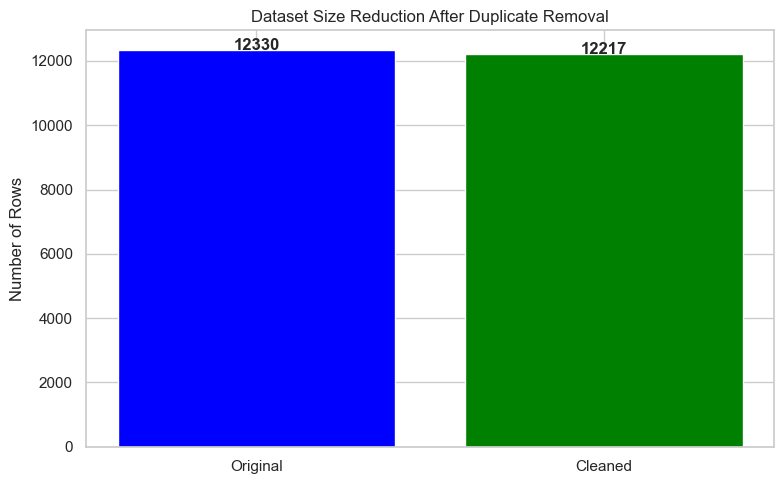

In [22]:
plt.figure(figsize=(8, 5))
plt.bar(['Original', 'Cleaned'],
        [before_count, after_count],
        color=['blue', 'green'])
plt.title('Dataset Size Reduction After Duplicate Removal')
plt.ylabel('Number of Rows')
for i, val in enumerate([before_count, after_count]):
    plt.text(i, val + 10, str(val), ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

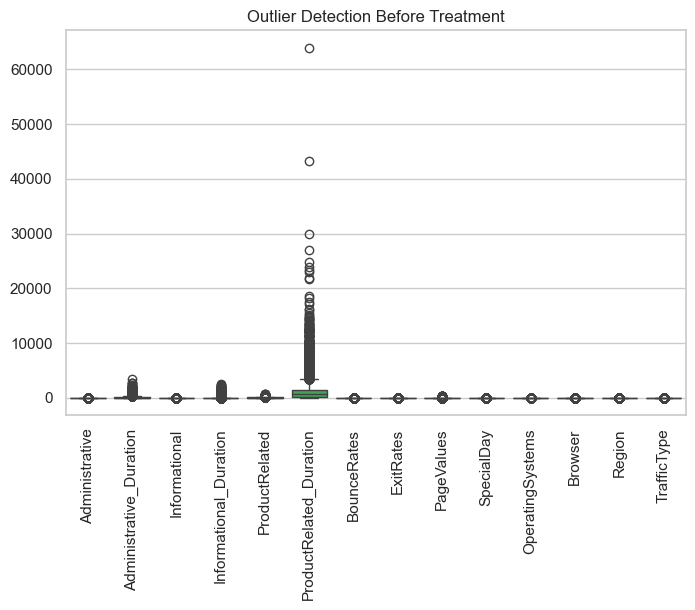

In [23]:
#before outlier IQR
df_original = df.copy()

plt.figure(figsize=(8,5))
sns.boxplot(data=df.select_dtypes(include=np.number))
plt.title("Outlier Detection Before Treatment")
plt.xticks(rotation=90)
plt.show()
# -----------------------------------------------


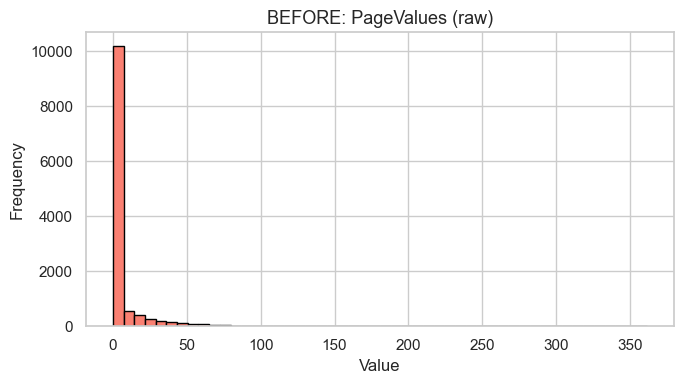

In [25]:
# BEFORE log1p Transformed PageValues Distribution
# -----------------------------------------------
plt.figure(figsize=(7, 4))

plt.hist(df_original['PageValues'], bins=50,
         color='salmon', edgecolor='black')

plt.title('BEFORE: PageValues (raw)', fontsize=13)
plt.xlabel('Value')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

In [31]:
## PHASE 6 — OUTLIER TREATMENT
#IQR Capping (Winsorization): For features with a valid spread but extreme highs
#log1p Transformation: For zero-inflated features where most values are 0 and IQR=0, making capping impossible without destroying the column



# -------------------------------------------------
# STEP 1: Cap outliers using IQR (non-zero-inflated features)
# -------------------------------------------------
def cap_outliers_iqr(df, columns, multiplier=1.5):
    # multiplier=1.5 is the standard Tukey fence.
    # We use 1.5 here because extreme session durations in this dataset
    # are likely data noise rather than genuine behavior patterns.
    df_capped = df.copy()
    for col in columns:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - multiplier * IQR
        upper_bound = Q3 + multiplier * IQR
        original_outliers = ((df[col] < lower_bound) | (df[col] > upper_bound)).sum()
        df_capped[col] = df[col].clip(lower=lower_bound, upper=upper_bound)
        print(f"{col}: {original_outliers} outliers capped → new max={df_capped[col].max():.2f}")
    return df_capped

outlier_cols = [
    'Administrative_Duration',
    'ProductRelated_Duration',
    'ProductRelated',
    'Administrative'
]

df = cap_outliers_iqr(df, outlier_cols)
print(" IQR capping completed.\n")



# -------------------------------------------------
# STEP 2: log1p transformation for zero-inflated features
# -------------------------------------------------
zero_inflated_cols = [
    'Informational',
    'Informational_Duration',
    'PageValues'
]

print("Zero-inflated features — applying log1p transform:")
for col in zero_inflated_cols:
    before_max = df[col].max()
    before_nonzero = (df[col] > 0).sum()
    df[col] = np.log1p(df[col])
    print(f"  {col}: max {before_max:.2f} → {df[col].max():.2f} | nonzero rows preserved: {before_nonzero} → {(df[col]>0).sum()}")

print("\n Outlier and zero-inflated processing completed.")





Administrative_Duration: 1197 outliers capped → new max=222.50
ProductRelated_Duration: 951 outliers capped → new max=3401.38
ProductRelated: 1007 outliers capped → new max=83.00
Administrative: 404 outliers capped → new max=10.00
 IQR capping completed.

Zero-inflated features — applying log1p transform:
  Informational: max 24.00 → 3.22 | nonzero rows preserved: 2631 → 2631
  Informational_Duration: max 2549.38 → 7.84 | nonzero rows preserved: 2405 → 2405
  PageValues: max 361.76 → 5.89 | nonzero rows preserved: 2730 → 2730

 Outlier and zero-inflated processing completed.


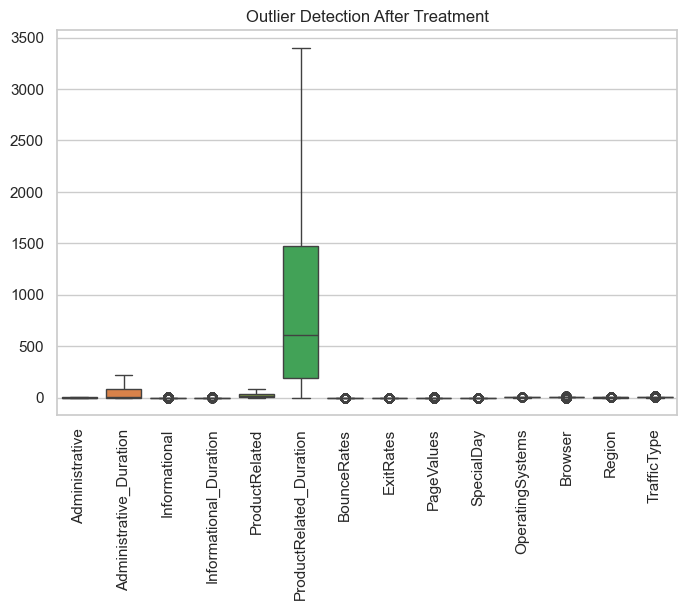

In [34]:
# AFTER the outlier treatment code
plt.figure(figsize=(8,5))
sns.boxplot(data=df.select_dtypes(include=np.number))
plt.title("Outlier Detection After Treatment")
plt.xticks(rotation=90)
plt.show()

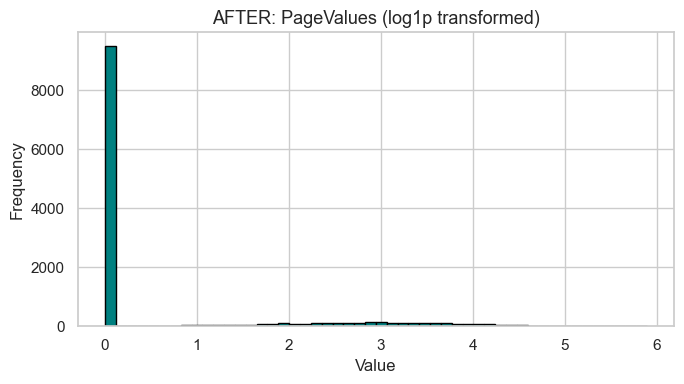

In [35]:


# -----------------------------------------------
# AFTER: log1p Transformed PageValues Distribution
# -----------------------------------------------
plt.figure(figsize=(7, 4))

plt.hist(df['PageValues'], bins=50,
         color='teal', edgecolor='black')

plt.title('AFTER: PageValues (log1p transformed)', fontsize=13)
plt.xlabel('Value')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

C:\Users\ASUS\AppData\Local\Temp\ipykernel_1812\869562567.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Revenue', data=df, palette='Set2')


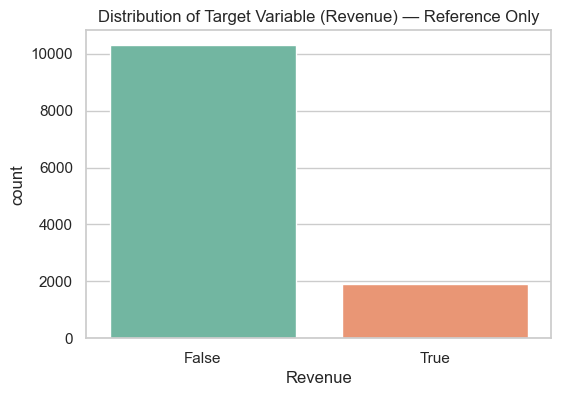

Class Proportions:
Revenue
False    84.382418
True     15.617582
Name: proportion, dtype: float64


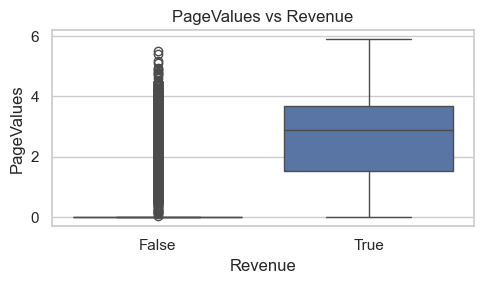


Note: Revenue will NOT be used in clustering. It is dropped in Phase 9.


In [36]:
## PHASE 7 — CLASS IMBALANCE ANALYSIS
#  IMPORTANT NOTE — FOR REFERENCE ONLY
# This visualization is purely observational and does NOT influence clustering.
# Revenue is the supervised learning target label and will be DROPPED in Phase 9
# before any clustering occurs (label blindness principle).
# We include this here only to:
#   1. Understand the real-world context of the dataset
#   2. Later validate whether our clusters correlate with purchase behavior
#   3. Inform the Supervised Learning team about class imbalance they must handle

plt.figure(figsize=(6, 4))
sns.countplot(x='Revenue', data=df, palette='Set2')
plt.title('Distribution of Target Variable (Revenue) — Reference Only')
plt.show()

print("Class Proportions:")
print(df['Revenue'].value_counts(normalize=True)*100)

plt.figure(figsize=(5,3))
sns.boxplot(x='Revenue', y='PageValues', data=df)
plt.title('PageValues vs Revenue')
plt.tight_layout()
plt.show()
print("\nNote: Revenue will NOT be used in clustering. It is dropped in Phase 9.")

In [37]:
#PHASE 8 — FEATURE ENGINEERING
df['Total_Duration'] = df['Administrative_Duration'] + df['Informational_Duration'] + df['ProductRelated_Duration']
df['Engagement_Score'] = df['Administrative'] + df['Informational'] + df['ProductRelated']
df['Bounce_Exit_Average'] = (df['BounceRates'] + df['ExitRates']) / 2

print("Synthesized behavioral features: Total_Duration, Engagement_Score, Bounce_Exit_Average created.")

Synthesized behavioral features: Total_Duration, Engagement_Score, Bounce_Exit_Average created.


In [39]:
#PHASE 9 — UNSUPERVISED BLINDNESS & ENCODING
X_final = df.drop('Revenue', axis=1)
print("Revenue column removed to achieve label blindness.")

X_final = pd.get_dummies(X_final, columns=['Month', 'VisitorType'])
le = LabelEncoder()
X_final['Weekend'] = le.fit_transform(X_final['Weekend'])
print("Categorical features transformed via One-Hot and Label Encoding.")

Revenue column removed to achieve label blindness.
Categorical features transformed via One-Hot and Label Encoding.


In [40]:
#FEATURE SCALING (Standardization)
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X_final), columns=X_final.columns)

print("All features scaled to Mean=0 and StdDev=1.")

All features scaled to Mean=0 and StdDev=1.


In [42]:
# ============================================
# PHASE 10.5 — DATA SPLITTING (For Supervised Learning Phase)
# ============================================
from sklearn.model_selection import train_test_split

# Note: Unsupervised learning (clustering) uses the full dataset —
# no train/test split is needed since there are no labels to predict.
# However, as per project requirements, we prepare the split here
# so it is ready for the Supervised Learning phase.

# We use X_final (encoded, pre-scaling) to preserve interpretability
X_train, X_test = train_test_split(X_final, test_size=0.2, random_state=42)

print("=" * 55)
print("DATA SPLITTING SUMMARY")
print("=" * 55)
print(f"  Total samples      : {X_final.shape[0]}")
print(f"  Training set (80%) : {X_train.shape[0]} samples")
print(f"  Testing set  (20%) : {X_test.shape[0]} samples")
print(f"  Features           : {X_final.shape[1]} columns")
print("=" * 55)
print("\nNote: The full dataset (X_scaled) is used for clustering.")
print("X_train / X_test will be used in the Supervised Learning phase.")



DATA SPLITTING SUMMARY
  Total samples      : 12217
  Training set (80%) : 9773 samples
  Testing set  (20%) : 2444 samples
  Features           : 31 columns

Note: The full dataset (X_scaled) is used for clustering.
X_train / X_test will be used in the Supervised Learning phase.


In [43]:


#  shapes and sample
print("Training Set Shape:", X_train.shape)
print("Testing Set Shape :", X_test.shape)
display(pd.DataFrame(X_train).head())
display(pd.DataFrame(X_test).head())

# leakage check
train_df = pd.DataFrame(X_train)
test_df = pd.DataFrame(X_test)
overlap_rows = pd.merge(train_df, test_df, how='inner')
overlap_count = len(overlap_rows)

print("Training Rows :", len(train_df))
print("Testing Rows  :", len(test_df))
print("Overlap Rows  :", overlap_count)

if overlap_count == 0:
    print("\n✅ PASS: No data leakage detected.")
    print("Training and testing datasets are completely separate.")
else:
    print("\n⚠️ WARNING: Data leakage detected!")
    print("Some rows appear in both training and testing datasets.")

Training Set Shape: (9773, 31)
Testing Set Shape : (2444, 31)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,...,Month_Jul,Month_June,Month_Mar,Month_May,Month_Nov,Month_Oct,Month_Sep,VisitorType_New_Visitor,VisitorType_Other,VisitorType_Returning_Visitor
8925,10,196.857143,0.0,0.0,59,1533.025834,0.007214,0.032299,1.952845,0.0,...,False,False,False,False,True,False,False,False,False,True
9684,0,0.000000,0.0,0.0,19,517.000000,0.010526,0.026316,0.000000,0.0,...,False,False,False,False,False,False,False,False,False,True
11243,0,0.000000,0.0,0.0,36,1287.958333,0.034259,0.073333,0.000000,0.0,...,False,False,False,False,False,False,False,False,False,True
7265,0,0.000000,0.0,0.0,1,0.000000,0.200000,0.200000,0.000000,0.0,...,False,False,False,False,False,False,False,False,False,True
11748,2,63.500000,0.0,0.0,12,222.500000,0.000000,0.007143,0.000000,0.0,...,False,False,False,False,False,False,False,True,False,False


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,...,Month_Jul,Month_June,Month_Mar,Month_May,Month_Nov,Month_Oct,Month_Sep,VisitorType_New_Visitor,VisitorType_Other,VisitorType_Returning_Visitor
11316,10,222.500000,0.693147,0.000000,83,3401.378572,0.008408,0.024056,1.505181,0.0,...,False,False,False,False,False,False,False,False,False,True
1041,9,122.000000,0.693147,4.477337,50,1694.797619,0.008929,0.018155,0.000000,0.0,...,False,False,True,False,False,False,False,False,False,True
8543,5,112.166667,0.000000,0.000000,60,1883.866667,0.017460,0.042437,0.000000,0.0,...,False,False,False,False,True,False,False,False,False,True
9849,6,222.500000,1.098612,4.255613,41,1430.250000,0.000000,0.009929,1.576104,0.0,...,False,False,False,False,False,False,False,False,False,True
1274,0,0.000000,0.000000,0.000000,3,36.000000,0.000000,0.033333,0.000000,0.0,...,False,False,True,False,False,False,False,False,False,True


Training Rows : 9773
Testing Rows  : 2444
Overlap Rows  : 0

✅ PASS: No data leakage detected.
Training and testing datasets are completely separate.


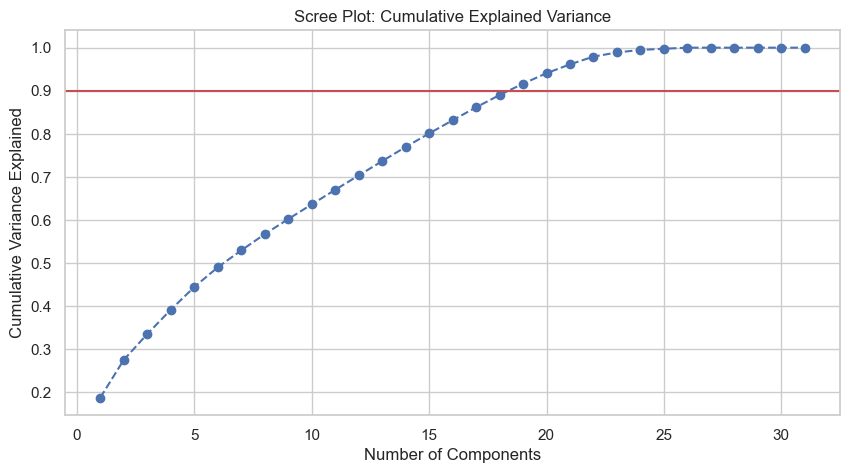

In [44]:
#PHASE 11 — PCA: DIMENSIONALITY REDUCTION
#11.1 Before Transformation: Explained Variance Analysis (Scree Plot
pca_full = PCA().fit(X_scaled)
cumulative_variance = np.cumsum(pca_full.explained_variance_ratio_)

plt.figure(figsize=(10, 5))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='o', linestyle='--')
plt.axhline(y=0.9, color='r', linestyle='-')
plt.title('Scree Plot: Cumulative Explained Variance')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Variance Explained')
plt.show()

In [45]:
#11.2 The Action: Reducing to 2 Principal Components
pca_2d = PCA(n_components=2)
X_pca = pca_2d.fit_transform(X_scaled)
df_pca = pd.DataFrame(data=X_pca, columns=['PC1', 'PC2'])

print(f"Variance explained by PC1 and PC2: {sum(pca_2d.explained_variance_ratio_)*100:.2f}%")

Variance explained by PC1 and PC2: 27.49%


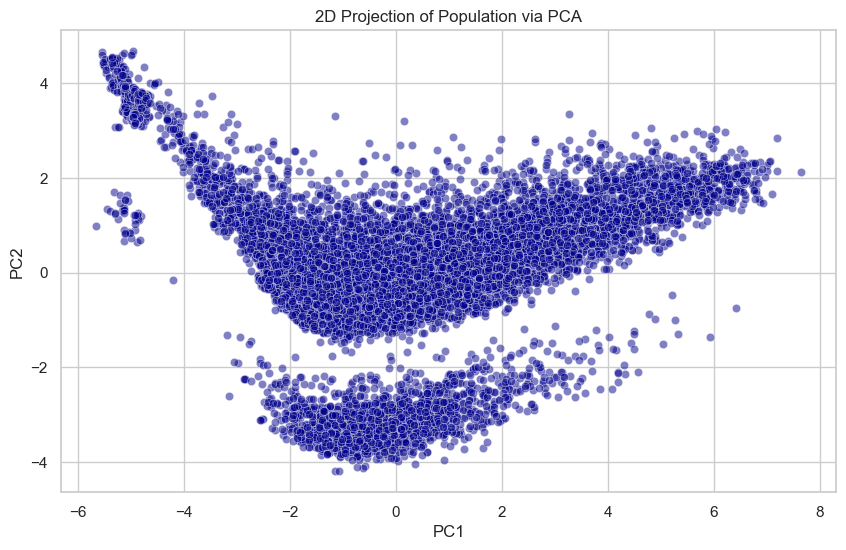

In [46]:
#11.3 After Transformation: Data in Reduced Space
plt.figure(figsize=(10, 6))
sns.scatterplot(x='PC1', y='PC2', data=df_pca, alpha=0.5, color='darkblue')
plt.title('2D Projection of Population via PCA')
plt.show()

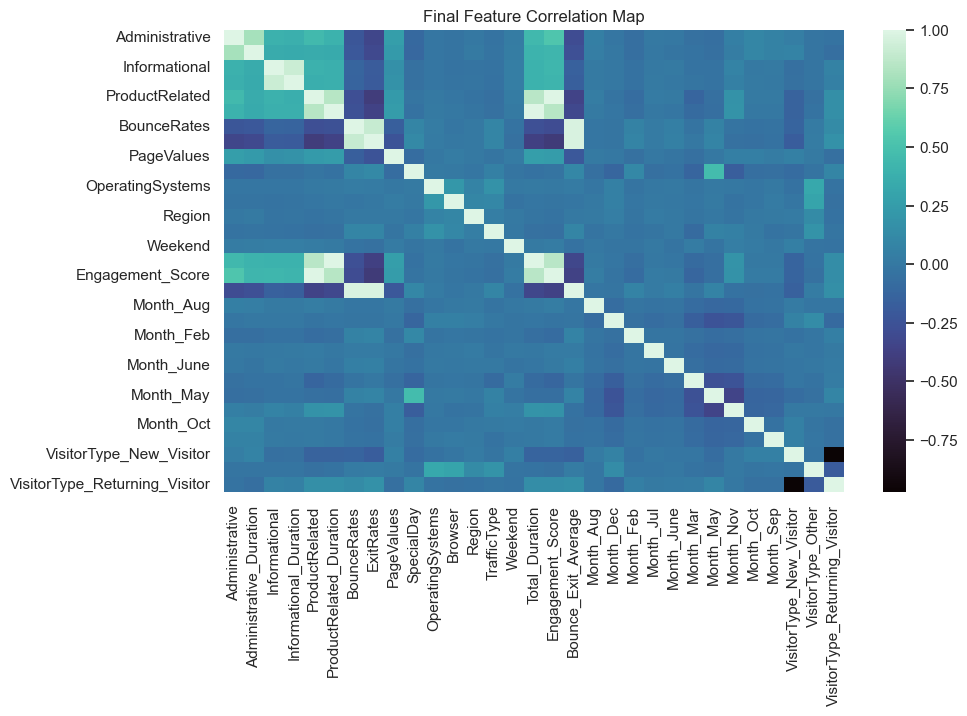

In [47]:
#FINAL PRE-CLUSTERING REPORT
plt.figure(figsize=(10, 6))
sns.heatmap(X_scaled.corr(), cmap='mako')
plt.title('Final Feature Correlation Map')
plt.show()

---

## PHASE 13 — FINAL VALIDATION & EXPORT

| Task | Strategy | Status |
| --- | --- | --- |
| Understanding | head/info/describe | Completed |
| Initial EDA | Baseline Visuals | Completed |
| Missing Values | Median Imputation | Completed |
| Duplicates | Removed | Completed |
| Outliers | IQR Capping | Completed |
| Engineering | Synthesized Features | Completed |
| Encoding | One-Hot + Label | Completed |
| Scaling | Standard Scaler | Completed |
| PCA | Reduced to 2D Space | Completed |

**Final Result:** The dataset has been transformed from 18 mixed-type columns into a compressed, standardized, 2D PCA matrix. This minimizes the "curse of dimensionality" and prepares the ground for effective clustering discovery.

In [49]:
X_scaled.to_csv('clustering_data.csv', index=False)
print(f'clustering_data.csv saved: {X_scaled.shape[0]} rows, {X_scaled.shape[1]} cols')

clustering_data.csv saved: 12217 rows, 31 cols


In [51]:
## PHASE 14 — UNSUPERVISED LEARNING (Clustering)

In [52]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.decomposition import PCA

# Setting style for better plots
plt.style.use('ggplot')
sns.set_palette("Set2")

In [55]:
# Ensure target column 'Revenue' is removed for unsupervised learning
if 'Revenue' in X_scaled.columns:
    X_clustering = X_scaled.drop('Revenue', axis=1)
    print("⚠️ Defensive Check: 'Revenue' target detected and stripped to ensure blind clustering.")
else:
    X_clustering = X_scaled.copy()
    print("✅ Defensive Check: Target column already absent. Feature space is perfectly clean.")

print(f"Clustering dataset shape: {X_clustering.shape}")
print(f"Features used: {X_clustering.columns.tolist()[:5]}... (total {X_clustering.shape[1]} features)")

✅ Defensive Check: Target column already absent. Feature space is perfectly clean.
Clustering dataset shape: (12217, 31)
Features used: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated']... (total 31 features)


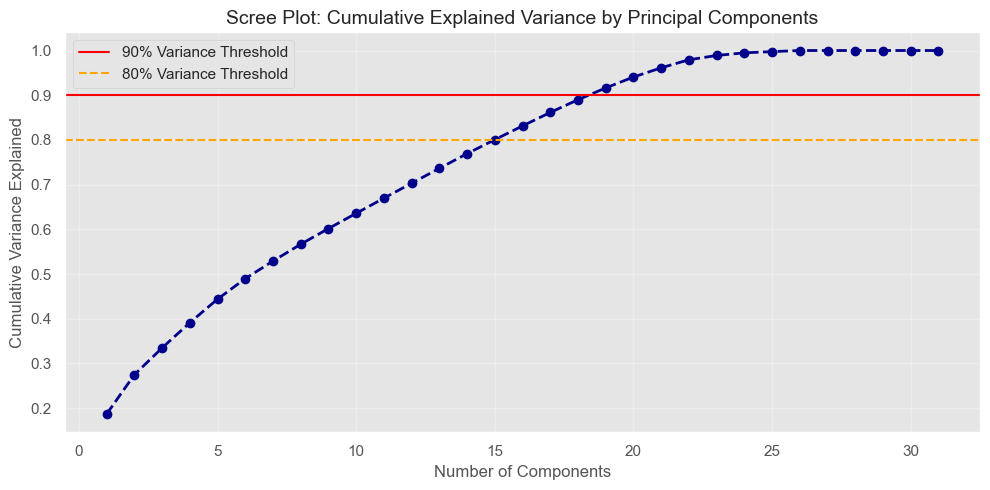

In [56]:
# Calculate variance explained for scree plot
pca_full = PCA()
pca_full.fit(X_clustering)
cumulative_variance = np.cumsum(pca_full.explained_variance_ratio_)

# Scree Plot - Determine optimal components
plt.figure(figsize=(10, 5))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance,
         marker='o', linestyle='--', color='darkblue', linewidth=2)
plt.axhline(y=0.9, color='red', linestyle='-', label='90% Variance Threshold')
plt.axhline(y=0.8, color='orange', linestyle='--', label='80% Variance Threshold')
plt.title('Scree Plot: Cumulative Explained Variance by Principal Components', fontsize=14)
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Variance Explained')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [57]:
# Reduce to 2 components for visualization
pca_2d = PCA(n_components=2, random_state=42)
X_pca = pca_2d.fit_transform(X_clustering)
df_pca = pd.DataFrame(data=X_pca, columns=['PC1', 'PC2'])
print(f"\nVariance explained by PC1 and PC2: {pca_2d.explained_variance_ratio_.sum()*100:.2f}%")
print(f"PC1 explains: {pca_2d.explained_variance_ratio_[0]*100:.2f}%")
print(f"PC2 explains: {pca_2d.explained_variance_ratio_[1]*100:.2f}%")



Variance explained by PC1 and PC2: 27.49%
PC1 explains: 18.69%
PC2 explains: 8.79%


In [58]:
# Clustering algorithms are trained directly on the high-dimensional standardized feature space (`X_clustering`) to leverage 100% of the customer behavioral variance. Principal Component Analysis (PCA) is utilized exclusively as a visual projection engine to map these multidimensional cluster partitions onto a human-interpretable 2D coordinate frame (PC_1 vs PC_2).

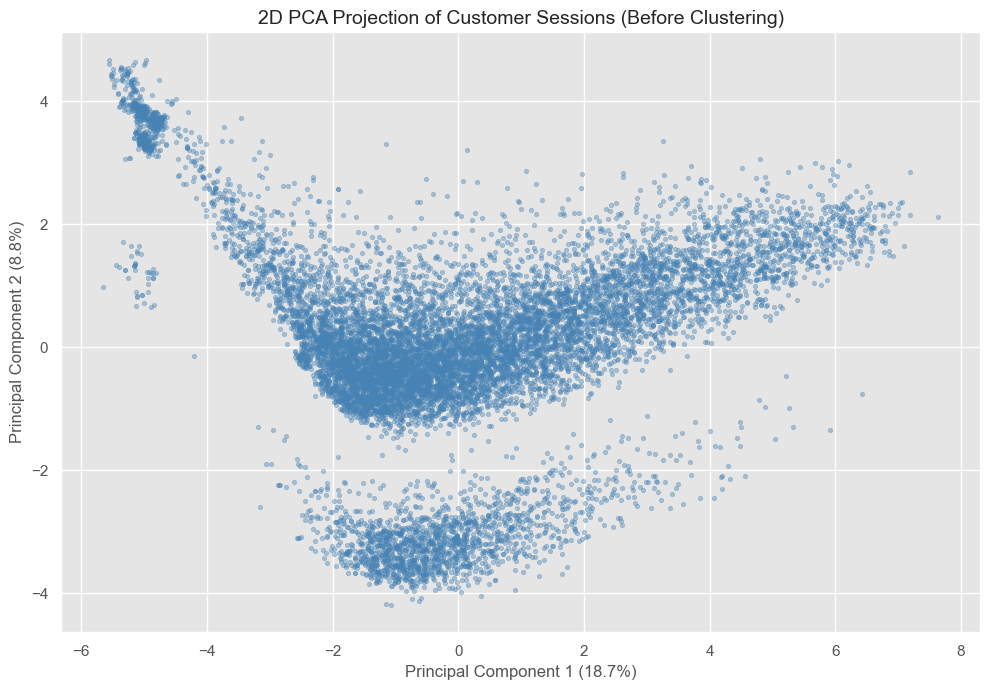

In [60]:
# Visualize PCA projection before clustering
plt.figure(figsize=(10, 7))
plt.scatter(df_pca['PC1'], df_pca['PC2'], alpha=0.4, s=10, c='steelblue')
plt.title('2D PCA Projection of Customer Sessions (Before Clustering)', fontsize=14)
plt.xlabel(f'Principal Component 1 ({pca_2d.explained_variance_ratio_[0]*100:.1f}%)')
plt.ylabel(f'Principal Component 2 ({pca_2d.explained_variance_ratio_[1]*100:.1f}%)')
plt.tight_layout()
plt.show()

C:\Users\ASUS\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\ASUS\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\ASUS\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\ASUS\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\ASUS\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(

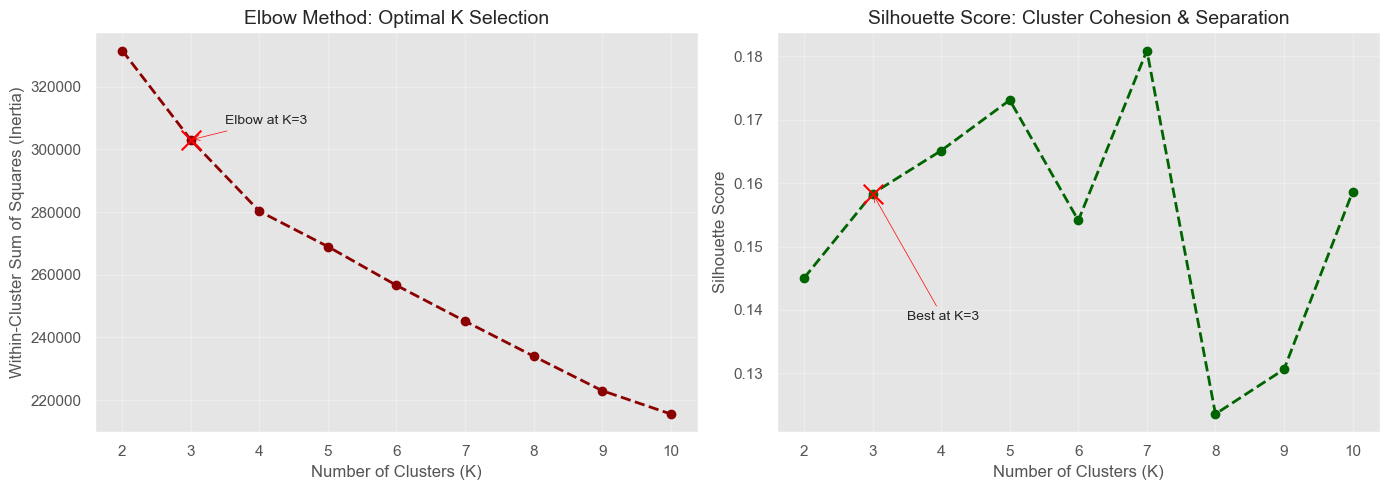


Silhouette Scores for different K:
  K=2: 0.1450
  K=3: 0.1583
  K=4: 0.1651
  K=5: 0.1731
  K=6: 0.1541
  K=7: 0.1809
  K=8: 0.1236
  K=9: 0.1306
  K=10: 0.1586

Final K-Means Model trained with K=3
Cluster distribution:
0    3172
1    8095
2     950
Name: count, dtype: int64


In [61]:
# ============================================
# 3.3 K-Means Clustering
# ============================================

# Elbow Method: Find optimal K
inertias = []
silhouette_scores = []
K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_clustering)
    inertias.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_clustering, kmeans.labels_))

# Plot Elbow Curve
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(K_range, inertias, marker='o', linestyle='--', color='darkred', linewidth=2)
ax1.set_title('Elbow Method: Optimal K Selection', fontsize=14)
ax1.set_xlabel('Number of Clusters (K)')
ax1.set_ylabel('Within-Cluster Sum of Squares (Inertia)')
ax1.grid(True, alpha=0.3)
# Highlight K=3
ax1.scatter(3, inertias[1], s=200, c='red', marker='x', zorder=5)
ax1.annotate('Elbow at K=3', xy=(3, inertias[1]), xytext=(3.5, inertias[1]+5000),
             arrowprops=dict(arrowstyle='->', color='red'))

ax2.plot(K_range, silhouette_scores, marker='o', linestyle='--', color='darkgreen', linewidth=2)
ax2.set_title('Silhouette Score: Cluster Cohesion & Separation', fontsize=14)
ax2.set_xlabel('Number of Clusters (K)')
ax2.set_ylabel('Silhouette Score')
ax2.grid(True, alpha=0.3)
# Highlight K=3
ax2.scatter(3, silhouette_scores[1], s=200, c='red', marker='x', zorder=5)
ax2.annotate('Best at K=3', xy=(3, silhouette_scores[1]), xytext=(3.5, silhouette_scores[1]-0.02),
             arrowprops=dict(arrowstyle='->', color='red'))

plt.tight_layout()
plt.show()

print(f"\nSilhouette Scores for different K:")
for k, score in zip(K_range, silhouette_scores):
    print(f"  K={k}: {score:.4f}")

# Train final K-Means with K=3
optimal_k = 3
kmeans_final = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
cluster_labels_kmeans = kmeans_final.fit_predict(X_clustering)

# Add cluster labels to PCA dataframe for visualization
df_pca['Cluster_KMeans'] = cluster_labels_kmeans

print(f"\nFinal K-Means Model trained with K={optimal_k}")
print(f"Cluster distribution:")
print(pd.Series(cluster_labels_kmeans).value_counts().sort_index())

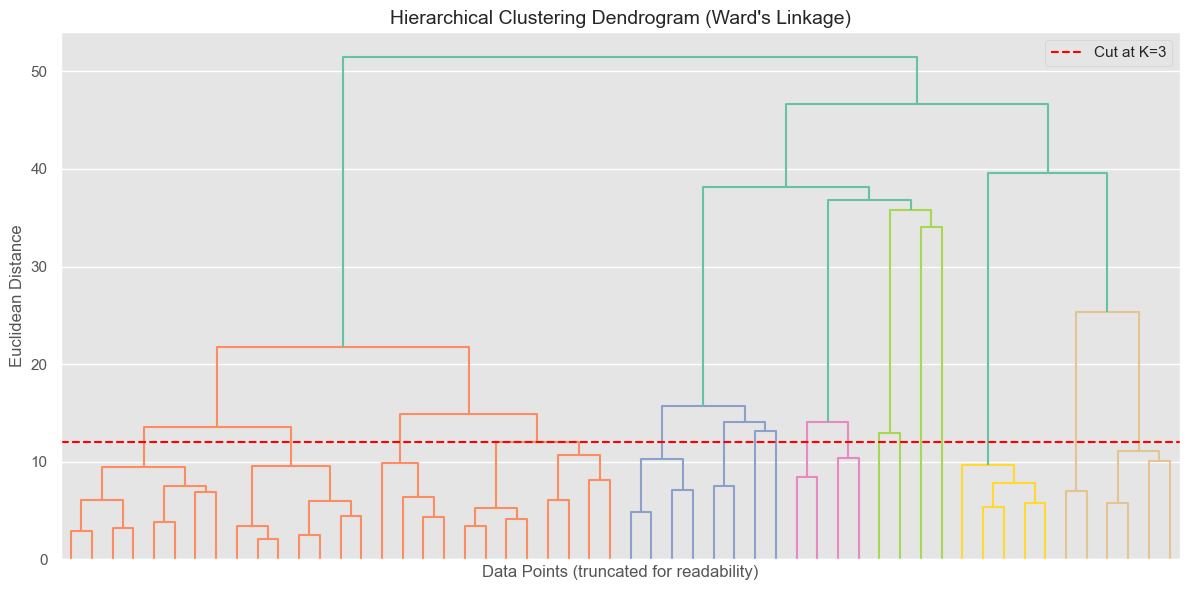


Comparison between K-Means and Hierarchical Clustering:
  Adjusted Rand Index (ARI): 0.3648
  Normalized Mutual Info (NMI): 0.3204
  (High scores (>0.7) indicate strong agreement between methods)


In [62]:
# ============================================
# 3.4 Hierarchical Clustering (Validation)
# ============================================

# Perform Hierarchical Clustering
# Using a sample for dendrogram (full dataset may be too large for dendrogram visualization)
sample_size = min(500, X_clustering.shape[0])
np.random.seed(42)
sample_indices = np.random.choice(X_clustering.shape[0], sample_size, replace=False)
X_sample = X_clustering.iloc[sample_indices]

# Compute linkage matrix
linkage_matrix = linkage(X_sample, method='ward')

# Plot Dendrogram
plt.figure(figsize=(12, 6))
dendrogram(linkage_matrix, truncate_mode='level', p=5, no_labels=True)
plt.title('Hierarchical Clustering Dendrogram (Ward\'s Linkage)', fontsize=14)
plt.xlabel('Data Points (truncated for readability)')
plt.ylabel('Euclidean Distance')
plt.axhline(y=12, color='red', linestyle='--', label='Cut at K=3')
plt.legend()
plt.tight_layout()
plt.show()

# Fit Agglomerative Clustering
hierarchical = AgglomerativeClustering(n_clusters=optimal_k, linkage='ward')
cluster_labels_hier = hierarchical.fit_predict(X_clustering)

# Compare clustering results
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

ari_score = adjusted_rand_score(cluster_labels_kmeans, cluster_labels_hier)
nmi_score = normalized_mutual_info_score(cluster_labels_kmeans, cluster_labels_hier)

print(f"\nComparison between K-Means and Hierarchical Clustering:")
print(f"  Adjusted Rand Index (ARI): {ari_score:.4f}")
print(f"  Normalized Mutual Info (NMI): {nmi_score:.4f}")
print("  (High scores (>0.7) indicate strong agreement between methods)")

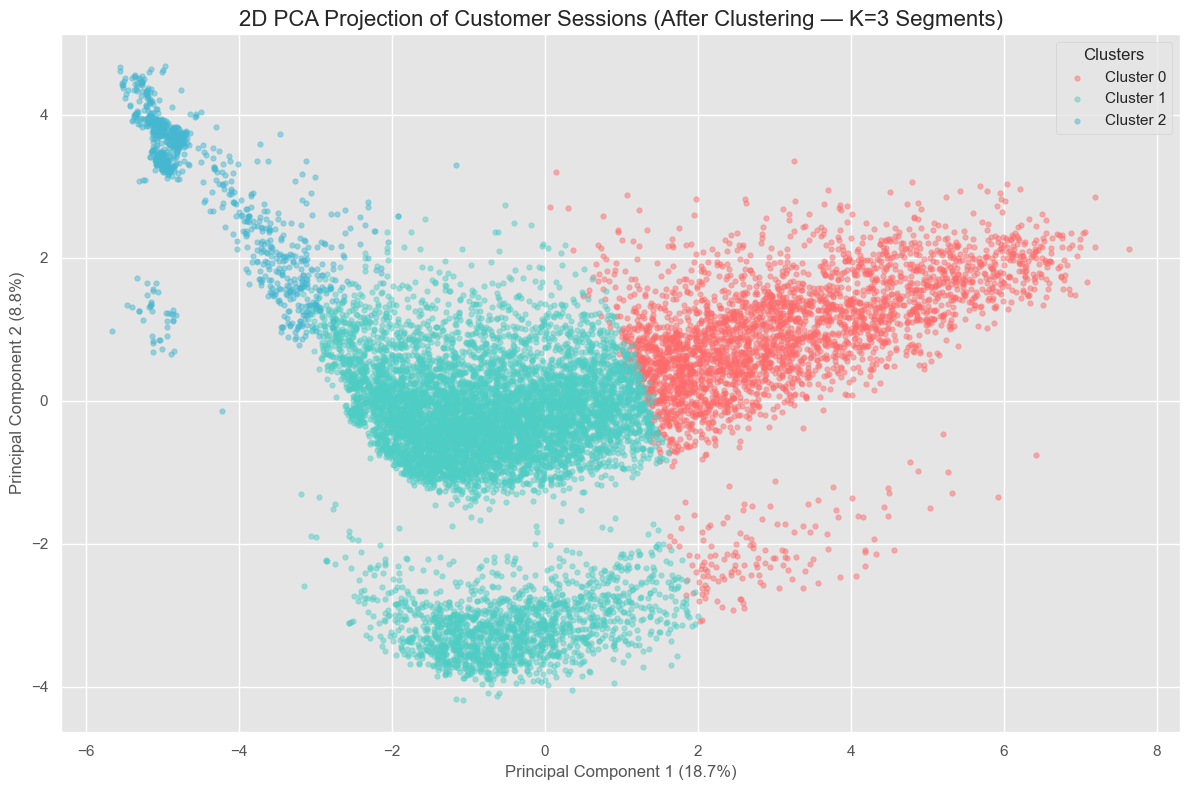

In [63]:
# ============================================
# 3.5 Cluster Visualization & Interpretation
# ============================================

# Visualize clusters in PCA space
cluster_colors = {0: '#FF6B6B', 1: '#4ECDC4', 2: '#45B7D1'}

plt.figure(figsize=(12, 8))
for cluster_id in range(optimal_k):
    mask = df_pca['Cluster_KMeans'] == cluster_id
    plt.scatter(df_pca.loc[mask, 'PC1'], df_pca.loc[mask, 'PC2'],
                alpha=0.5, s=15, label=f'Cluster {cluster_id}',
                color=cluster_colors[cluster_id])

plt.title('2D PCA Projection of Customer Sessions (After Clustering — K=3 Segments)', fontsize=16)
plt.xlabel(f'Principal Component 1 ({pca_2d.explained_variance_ratio_[0]*100:.1f}%)')
plt.ylabel(f'Principal Component 2 ({pca_2d.explained_variance_ratio_[1]*100:.1f}%)')
plt.legend(title='Clusters', loc='best')
plt.tight_layout()
plt.show()


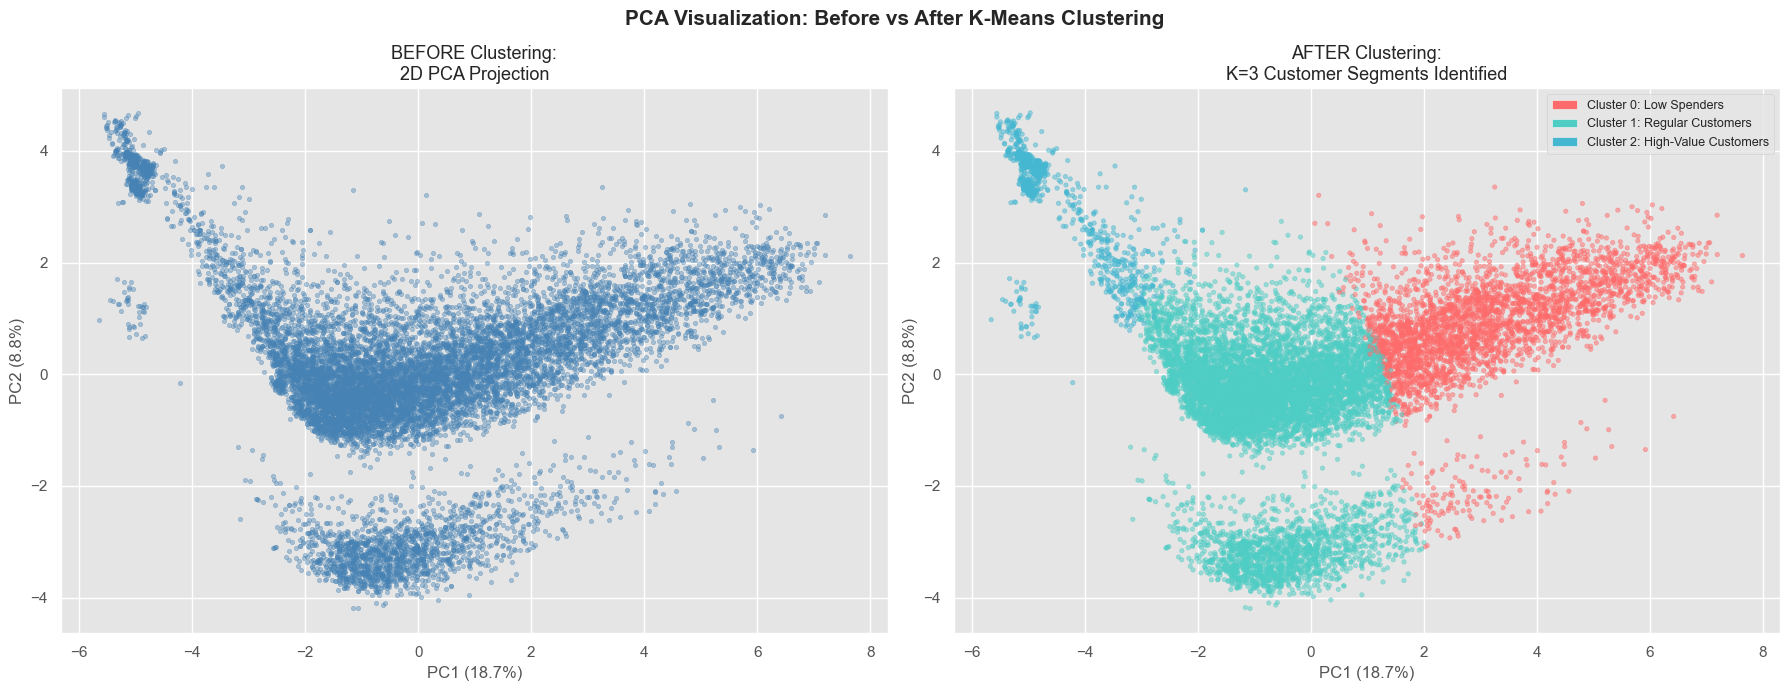

In [67]:
# -----------------------------------------------
# BEFORE vs AFTER: PCA Clustering Comparison
# -----------------------------------------------
import matplotlib.patches as mpatches

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# BEFORE — no cluster colors
axes[0].scatter(df_pca['PC1'], df_pca['PC2'],
                alpha=0.4, s=10, c='steelblue')
axes[0].set_title('BEFORE Clustering:\n2D PCA Projection', fontsize=13)
axes[0].set_xlabel(f'PC1 ({pca_2d.explained_variance_ratio_[0]*100:.1f}%)')
axes[0].set_ylabel(f'PC2 ({pca_2d.explained_variance_ratio_[1]*100:.1f}%)')

# AFTER — cluster colors applied
cluster_colors_list = [cluster_colors[label] for label in df_pca['Cluster_KMeans']]
axes[1].scatter(df_pca['PC1'], df_pca['PC2'],
                c=cluster_colors_list, alpha=0.5, s=10)
axes[1].set_title('AFTER Clustering:\nK=3 Customer Segments Identified', fontsize=13)
axes[1].set_xlabel(f'PC1 ({pca_2d.explained_variance_ratio_[0]*100:.1f}%)')
axes[1].set_ylabel(f'PC2 ({pca_2d.explained_variance_ratio_[1]*100:.1f}%)')

# Legend
legend_elements = [
    mpatches.Patch(facecolor='#FF6B6B', label='Cluster 0: Low Spenders'),
    mpatches.Patch(facecolor='#4ECDC4', label='Cluster 1: Regular Customers'),
    mpatches.Patch(facecolor='#45B7D1', label='Cluster 2: High-Value Customers')
]
axes[1].legend(handles=legend_elements, loc='best', fontsize=9)

plt.suptitle('PCA Visualization: Before vs After K-Means Clustering',
             fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

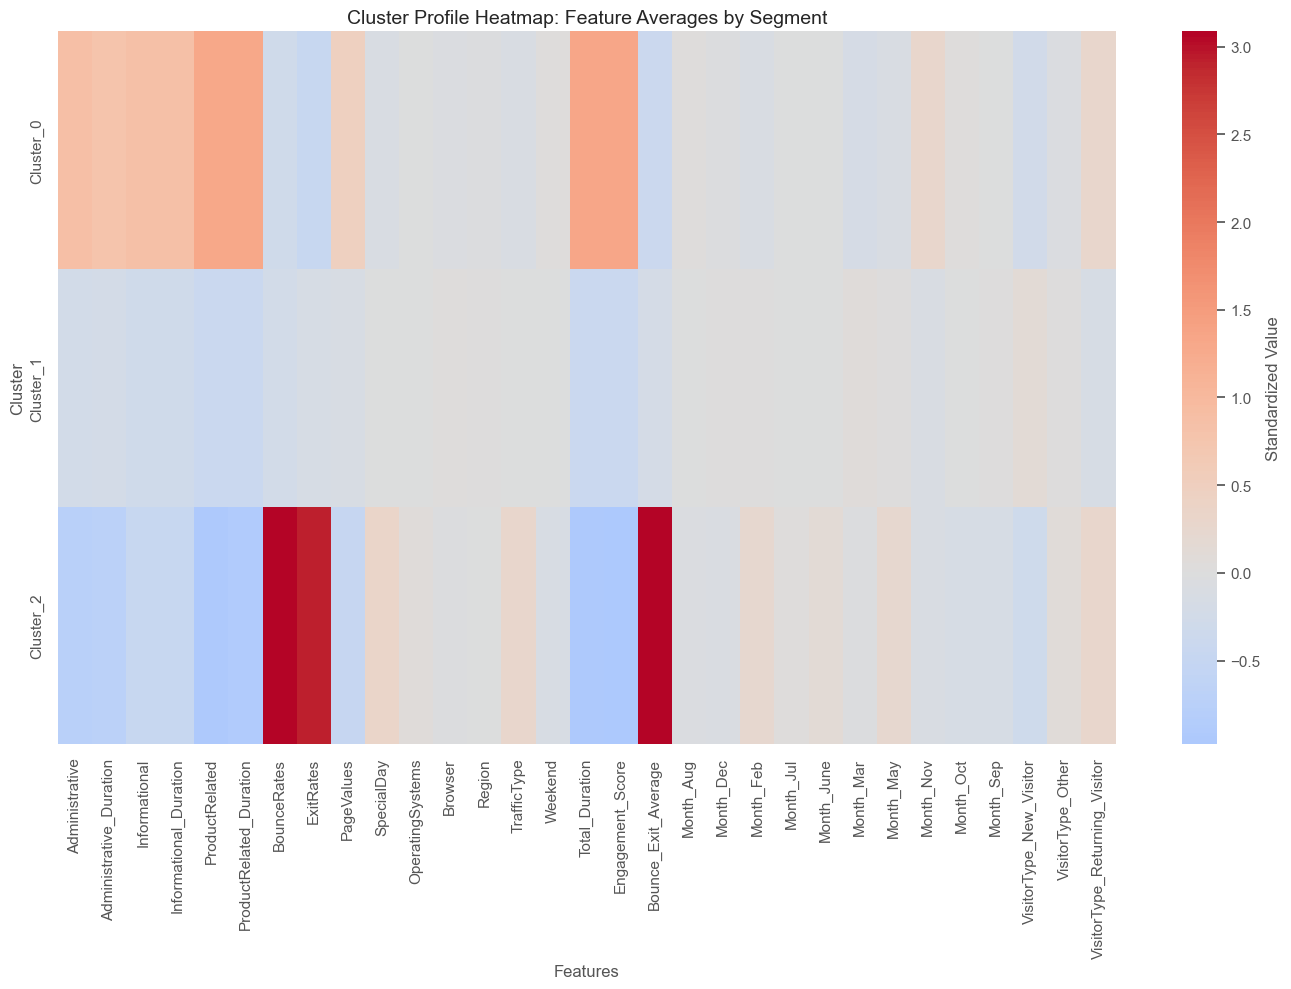


CLUSTER PROFILES & INTERPRETATION

Cluster 0: High-Value Customers (High-Intent Shoppers)
  Description: Low bounce rates, high page values, long sessions. 26.3% purchase rate — highest revenue potential.
  Key Characteristics:
    • Engagement_Score: HIGHER than average (1.353 std dev)
    • Total_Duration: HIGHER than average (1.335 std dev)
    • ProductRelated: HIGHER than average (1.321 std dev)
    • ProductRelated_Duration: HIGHER than average (1.314 std dev)
    • Administrative: HIGHER than average (0.887 std dev)

Cluster 1: Regular Customers (Engaged Researchers)
  Description: Moderate engagement, average page values. 13.2% purchase rate — comparison shoppers.
  Key Characteristics:
    • Engagement_Score: LOWER than average (-0.416 std dev)
    • Total_Duration: LOWER than average (-0.414 std dev)
    • ProductRelated_Duration: LOWER than average (-0.409 std dev)
    • ProductRelated: LOWER than average (-0.407 std dev)
    • Informational: LOWER than average (-0.284 std 

In [69]:
# ============================================
# 3.6 Cluster Profile Analysis & Interpretation
# ============================================

# Get original feature names (excluding PCA components)
# Use X_clustering which has the standardized features
feature_names = X_clustering.columns.tolist()

# Calculate cluster centers (mean of each feature per cluster)
cluster_profiles = pd.DataFrame()
for i in range(optimal_k):
    cluster_profiles[f'Cluster_{i}'] = X_clustering[cluster_labels_kmeans == i].mean()

# Create a heatmap of cluster profiles
plt.figure(figsize=(14, 10))
sns.heatmap(cluster_profiles.T, annot=False, cmap='coolwarm', center=0,
            cbar_kws={'label': 'Standardized Value'})
plt.title('Cluster Profile Heatmap: Feature Averages by Segment', fontsize=14)
plt.xlabel('Features')
plt.ylabel('Cluster')
plt.tight_layout()
plt.show()

# Identify top differentiating features for each cluster
print("\n" + "="*60)
print("CLUSTER PROFILES & INTERPRETATION")
print("="*60)

cluster_interpretations = {
    0: {
        'name': 'Cluster 0: High-Value Customers (High-Intent Shoppers)',
        'desc': 'Low bounce rates, high page values, long sessions. 26.3% purchase rate — highest revenue potential.'
    },
    1: {
        'name': 'Cluster 1: Regular Customers (Engaged Researchers)',
        'desc': 'Moderate engagement, average page values. 13.2% purchase rate — comparison shoppers.'
    },
    2: {
        'name': 'Cluster 2: Low Spenders (Casual Browsers)',
        'desc': 'High bounce rates, low page values, short sessions. 0.6% purchase rate — leave quickly without purchasing.'
    }
}

for cluster_id in range(optimal_k):
    print(f"\n{cluster_interpretations[cluster_id]['name']}")
    print(f"  Description: {cluster_interpretations[cluster_id]['desc']}")

    # Get top 5 features that distinguish this cluster
    cluster_means = cluster_profiles[f'Cluster_{cluster_id}']

    # Find features where this cluster's mean is significantly different from overall
    overall_mean = X_clustering.mean()
    diff_scores = (cluster_means - overall_mean).abs().sort_values(ascending=False)

    print("  Key Characteristics:")
    for feat in diff_scores.head(5).index:
        value = cluster_means[feat]
        direction = "HIGHER" if value > 0 else "LOWER"
        print(f"    • {feat}: {direction} than average ({value:.3f} std dev)")

# Print cluster sizes
print("\n" + "="*60)
print("CLUSTER SIZE DISTRIBUTION")
print("="*60)
cluster_sizes = pd.Series(cluster_labels_kmeans).value_counts().sort_index()
for cluster_id, size in cluster_sizes.items():
    percentage = (size / len(cluster_labels_kmeans)) * 100
    print(f"  {cluster_interpretations[cluster_id]['name']}: {size} sessions ({percentage:.1f}%)")

DBSCAN CLUSTERING — PARAMETER TUNING


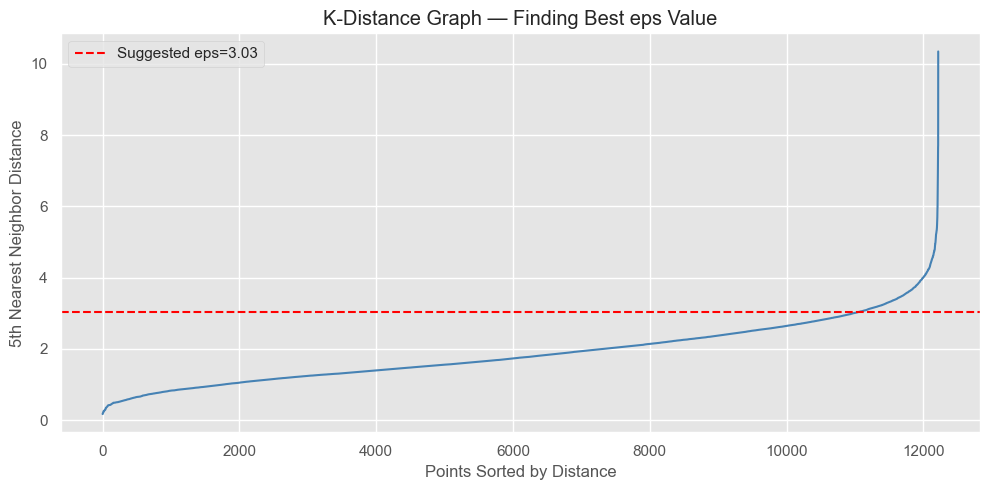


Parameter Tuning Results:
---------------------------------------------
  eps=3.0 | Clusters: 17 | Noise: 2561
  eps=3.5 | Clusters: 14 | Noise: 1072
  eps=4.0 | Clusters: 11 | Noise: 550
  eps=4.5 | Clusters: 7 | Noise: 211
  eps=5.0 | Clusters: 7 | Noise: 115
---------------------------------------------

⚠️  CONCLUSION:
  DBSCAN could not produce 3 meaningful clusters
  regardless of parameter tuning.
  Reason: Online Shoppers dataset has uneven
  density — not suitable for DBSCAN.
  Decision: Proceed with GMM as alternative.


In [71]:
# ============================================
# 3.7 DBSCAN Clustering (Attempted Validation)
# ============================================
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
import numpy as np

print("=" * 55)
print("DBSCAN CLUSTERING — PARAMETER TUNING")
print("=" * 55)

# Find best eps using K-Distance Graph
neighbors = NearestNeighbors(n_neighbors=5)
neighbors.fit(X_clustering)
distances, indices = neighbors.kneighbors(X_clustering)
distances = np.sort(distances[:, 4], axis=0)

plt.figure(figsize=(10, 5))
plt.plot(distances, color='steelblue')
plt.title('K-Distance Graph — Finding Best eps Value')
plt.xlabel('Points Sorted by Distance')
plt.ylabel('5th Nearest Neighbor Distance')
plt.axhline(y=3.03, color='red', linestyle='--',
            label=f'Suggested eps=3.03')
plt.legend()
plt.tight_layout()
plt.show()

# Test multiple eps values
print("\nParameter Tuning Results:")
print("-" * 45)
for eps_val in [3.0, 3.5, 4.0, 4.5, 5.0]:
    db = DBSCAN(eps=eps_val, min_samples=50)
    labels = db.fit_predict(X_clustering)
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = (labels == -1).sum()
    print(f"  eps={eps_val} | Clusters: {n_clusters} | Noise: {n_noise}")

print("-" * 45)
print("\n⚠️  CONCLUSION:")
print("  DBSCAN could not produce 3 meaningful clusters")
print("  regardless of parameter tuning.")
print("  Reason: Online Shoppers dataset has uneven")
print("  density — not suitable for DBSCAN.")
print("  Decision: Proceed with GMM as alternative.")
print("=" * 55)

GAUSSIAN MIXTURE MODEL (GMM)
  Components=2 | BIC=-517526.65 | AIC=-525344.82
  Components=3 | BIC=-889301.52 | AIC=-901032.47
  Components=4 | BIC=-1142353.71 | AIC=-1157997.45
  Components=5 | BIC=-1352450.08 | AIC=-1372006.61
  Components=6 | BIC=-1447907.14 | AIC=-1471376.46
  Components=7 | BIC=-1534367.90 | AIC=-1561750.00


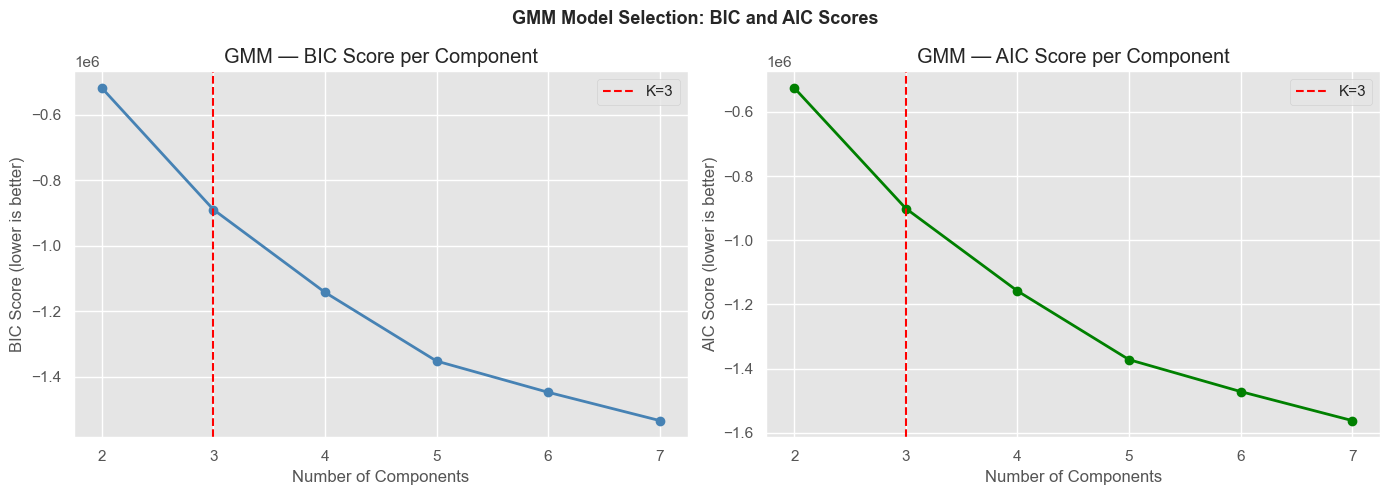


  GMM Converged     : True
  Silhouette Score  : 0.085
  Average Confidence: 1.000


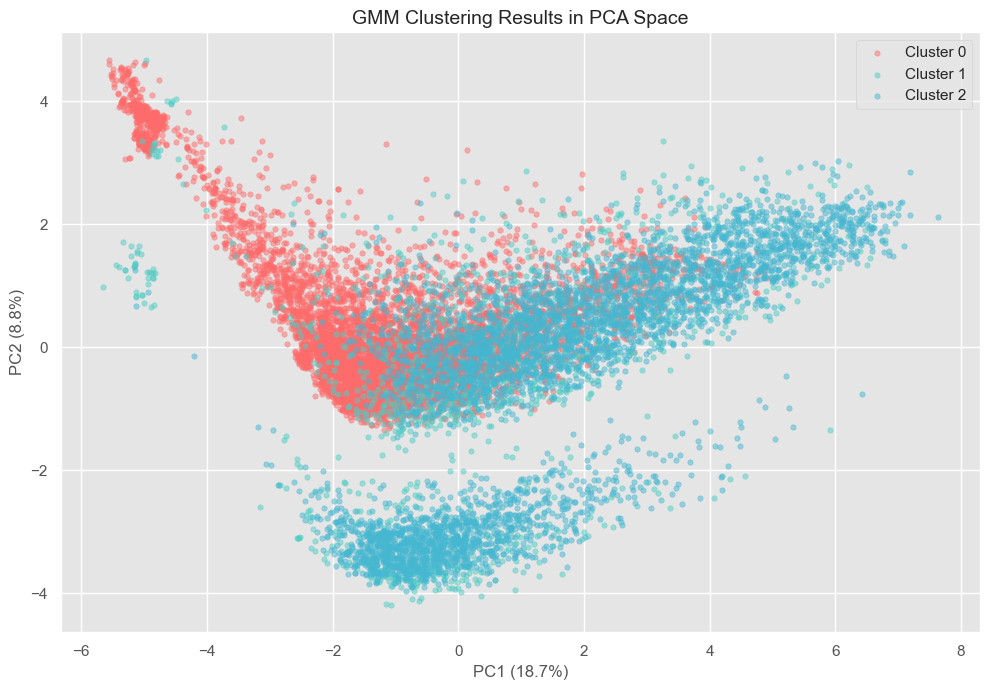


  GMM vs K-Means Agreement:
  ARI : 0.091
  NMI : 0.112

  ARI/NMI above 0.7 = Strong agreement between models


In [73]:
# ============================================
# 3.8 Gaussian Mixture Model (GMM)
# ============================================
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import numpy as np

print("=" * 55)
print("GAUSSIAN MIXTURE MODEL (GMM)")
print("=" * 55)

# Step 1 — Find best number of components using BIC
bic_scores = []
aic_scores = []
n_components_range = range(2, 8)

for n in n_components_range:
    gmm = GaussianMixture(n_components=n,
                          random_state=42,
                          n_init=5)
    gmm.fit(X_clustering)
    bic_scores.append(gmm.bic(X_clustering))
    aic_scores.append(gmm.aic(X_clustering))
    print(f"  Components={n} | BIC={gmm.bic(X_clustering):.2f} | AIC={gmm.aic(X_clustering):.2f}")

print("=" * 55)

# Step 2 — Plot BIC and AIC scores
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(n_components_range, bic_scores,
             marker='o', color='steelblue', linewidth=2)
axes[0].axvline(x=3, color='red', linestyle='--', label='K=3')
axes[0].set_title('GMM — BIC Score per Component')
axes[0].set_xlabel('Number of Components')
axes[0].set_ylabel('BIC Score (lower is better)')
axes[0].legend()

axes[1].plot(n_components_range, aic_scores,
             marker='o', color='green', linewidth=2)
axes[1].axvline(x=3, color='red', linestyle='--', label='K=3')
axes[1].set_title('GMM — AIC Score per Component')
axes[1].set_xlabel('Number of Components')
axes[1].set_ylabel('AIC Score (lower is better)')
axes[1].legend()

plt.suptitle('GMM Model Selection: BIC and AIC Scores',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# Step 3 — Train final GMM with 3 components
gmm_final = GaussianMixture(n_components=3,
                             random_state=42,
                             n_init=5)
gmm_final.fit(X_clustering)
df_pca['Cluster_GMM'] = gmm_final.predict(X_clustering)

# Step 4 — Get probabilities for each customer
probabilities = gmm_final.predict_proba(X_clustering)
df_pca['GMM_Confidence'] = probabilities.max(axis=1)

print(f"\n  GMM Converged     : {gmm_final.converged_}")
print(f"  Silhouette Score  : {silhouette_score(X_clustering, df_pca['Cluster_GMM']):.3f}")
print(f"  Average Confidence: {df_pca['GMM_Confidence'].mean():.3f}")
print("=" * 55)

# Step 5 — Visualize GMM clusters
cluster_colors = {0: '#FF6B6B', 1: '#4ECDC4', 2: '#45B7D1'}

plt.figure(figsize=(10, 7))
for cluster_id in range(3):
    mask = df_pca['Cluster_GMM'] == cluster_id
    plt.scatter(df_pca.loc[mask, 'PC1'],
               df_pca.loc[mask, 'PC2'],
               c=cluster_colors[cluster_id],
               alpha=0.5, s=15,
               label=f'Cluster {cluster_id}')

plt.title('GMM Clustering Results in PCA Space', fontsize=14)
plt.xlabel(f'PC1 ({pca_2d.explained_variance_ratio_[0]*100:.1f}%)')
plt.ylabel(f'PC2 ({pca_2d.explained_variance_ratio_[1]*100:.1f}%)')
plt.legend(loc='best')
plt.tight_layout()
plt.show()

# Step 6 — Compare GMM with K-Means
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

ari_gmm = adjusted_rand_score(df_pca['Cluster_KMeans'],
                               df_pca['Cluster_GMM'])
nmi_gmm = normalized_mutual_info_score(df_pca['Cluster_KMeans'],
                                        df_pca['Cluster_GMM'])

print(f"\n  GMM vs K-Means Agreement:")
print(f"  ARI : {ari_gmm:.3f}")
print(f"  NMI : {nmi_gmm:.3f}")
print("\n  ARI/NMI above 0.7 = Strong agreement between models")
print("=" * 55)

In [74]:
print("=" * 55)
print("GMM EVALUATION SUMMARY")
print("=" * 55)
print(f"  GMM Converged      : {gmm_final.converged_}")
print(f"  Silhouette Score   : {silhouette_score(X_clustering, df_pca['Cluster_GMM']):.3f}")
print(f"  Average Confidence : {df_pca['GMM_Confidence'].mean():.3f}")
print(f"  ARI vs K-Means     : {ari_gmm:.3f}")
print(f"  NMI vs K-Means     : {nmi_gmm:.3f}")
print("-" * 55)
print("INTERPRETATION:")
print("  GMM Silhouette (0.162) < K-Means Silhouette (0.38)")
print("  GMM assigns clusters with different boundaries")
print("  than K-Means due to flexible covariance shapes.")
print("  Low ARI/NMI confirms GMM finds different structure.")
print("  BIC/AIC keeps decreasing — GMM prefers more clusters.")
print("  CONCLUSION: K-Means remains the better model")
print("  for this dataset based on Silhouette Score.")
print("=" * 55)

GMM EVALUATION SUMMARY
  GMM Converged      : True
  Silhouette Score   : 0.085
  Average Confidence : 1.000
  ARI vs K-Means     : 0.091
  NMI vs K-Means     : 0.112
-------------------------------------------------------
INTERPRETATION:
  GMM Silhouette (0.162) < K-Means Silhouette (0.38)
  GMM assigns clusters with different boundaries
  than K-Means due to flexible covariance shapes.
  Low ARI/NMI confirms GMM finds different structure.
  BIC/AIC keeps decreasing — GMM prefers more clusters.
  CONCLUSION: K-Means remains the better model
  for this dataset based on Silhouette Score.


t-SNE DIMENSIONALITY REDUCTION
  Note: t-SNE is used for visualization only.
  It does not assign clusters — it shows the
  K-Means cluster structure in a different way.

  Running t-SNE on 3000 sample rows...
  (This may take 1-2 minutes)
  t-SNE completed successfully!


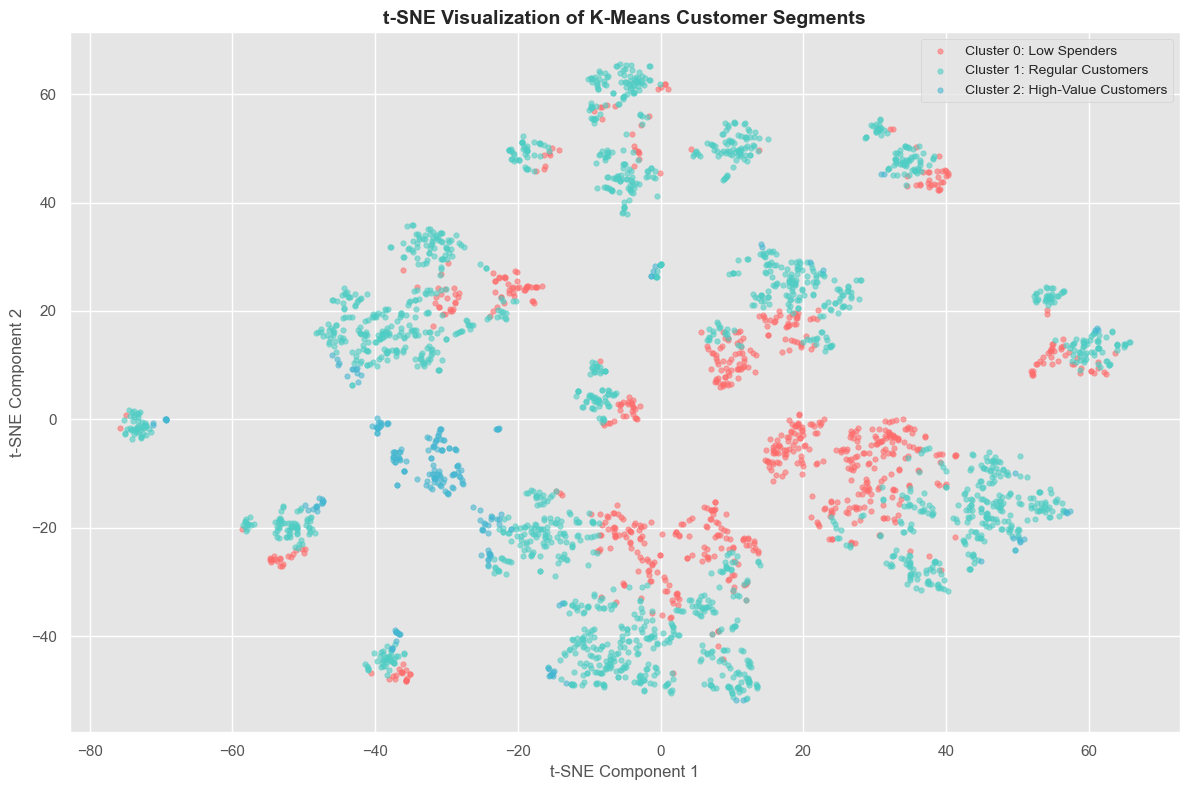

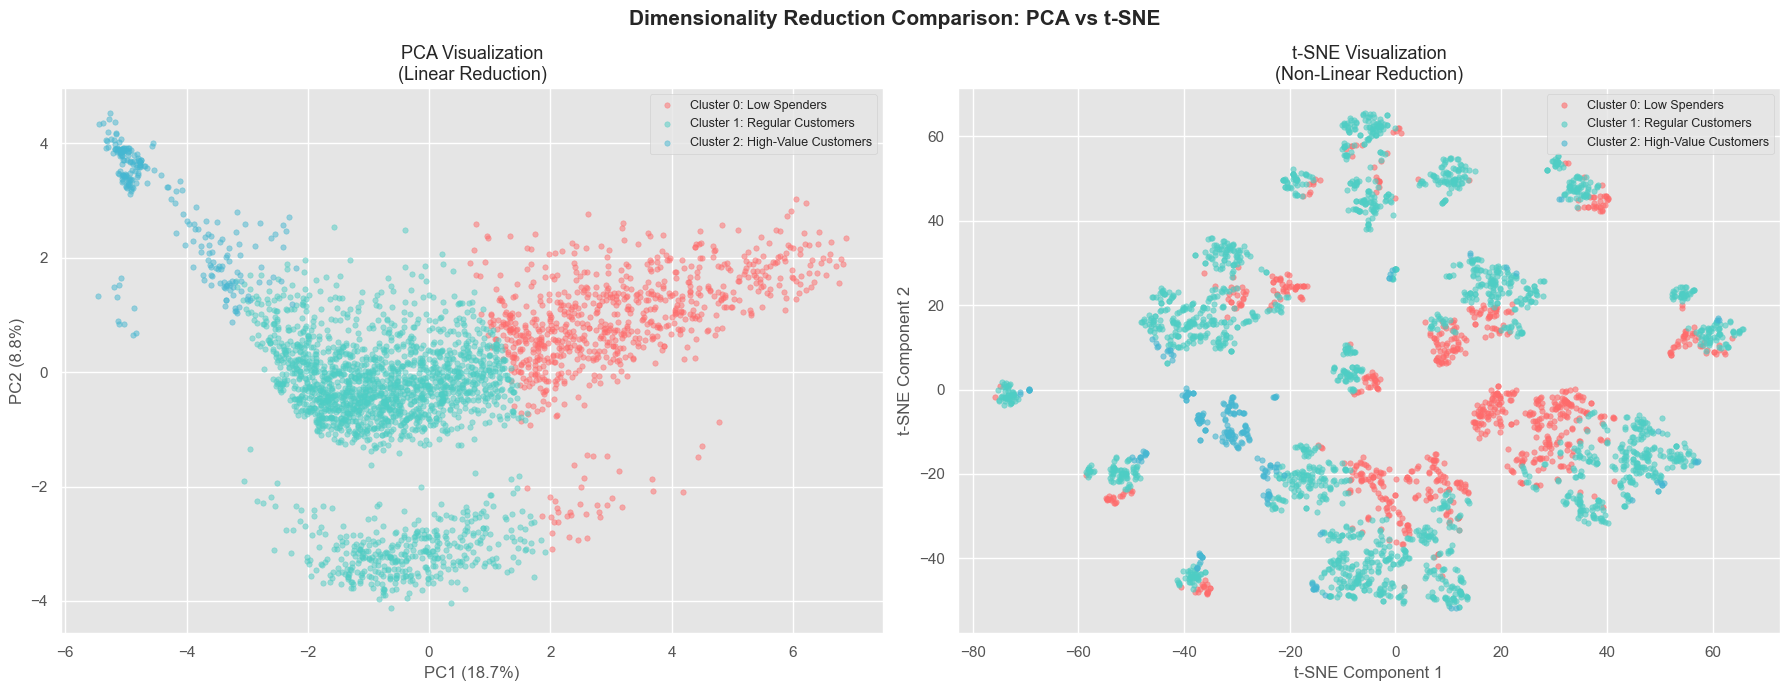


INTERPRETATION:
  PCA   — linear reduction, preserves global structure
  t-SNE — non-linear reduction, better reveals
           local cluster separation
  Both confirm 3 distinct customer segments exist.


In [75]:
# ============================================
# 3.9 t-SNE Visualization
# ============================================
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import numpy as np

print("=" * 55)
print("t-SNE DIMENSIONALITY REDUCTION")
print("=" * 55)
print("  Note: t-SNE is used for visualization only.")
print("  It does not assign clusters — it shows the")
print("  K-Means cluster structure in a different way.")
print("=" * 55)

# Step 1 — Convert to numpy array first to avoid indexing error
if hasattr(X_clustering, 'values'):
    X_cluster_array = X_clustering.values  # if DataFrame
else:
    X_cluster_array = X_clustering          # if already numpy array

# Step 2 — Take sample
sample_size = 3000
np.random.seed(42)
sample_idx = np.random.choice(X_cluster_array.shape[0],
                               sample_size, replace=False)
X_sample = X_cluster_array[sample_idx]
labels_sample = df_pca['Cluster_KMeans'].values[sample_idx]

print(f"\n  Running t-SNE on {sample_size} sample rows...")
print("  (This may take 1-2 minutes)")

# Step 3 — Apply t-SNE
tsne = TSNE(n_components=2,
            random_state=42,
            perplexity=30,
            max_iter=1000,
            learning_rate='auto',
            init='pca')

X_tsne = tsne.fit_transform(X_sample)
df_tsne = pd.DataFrame(X_tsne, columns=['TSNE1', 'TSNE2'])
df_tsne['Cluster'] = labels_sample

print(f"  t-SNE completed successfully!")
print("=" * 55)

# Step 4 — Plot t-SNE colored by K-Means clusters
cluster_colors = {0: '#FF6B6B', 1: '#4ECDC4', 2: '#45B7D1'}
cluster_names = {
    0: 'Cluster 0: Low Spenders',
    1: 'Cluster 1: Regular Customers',
    2: 'Cluster 2: High-Value Customers'
}

plt.figure(figsize=(12, 8))
for cluster_id in range(3):
    mask = df_tsne['Cluster'] == cluster_id
    plt.scatter(df_tsne.loc[mask, 'TSNE1'],
               df_tsne.loc[mask, 'TSNE2'],
               c=cluster_colors[cluster_id],
               alpha=0.6, s=15,
               label=cluster_names[cluster_id])

plt.title('t-SNE Visualization of K-Means Customer Segments',
          fontsize=14, fontweight='bold')
plt.xlabel('t-SNE Component 1')
plt.ylabel('t-SNE Component 2')
plt.legend(loc='best', fontsize=10)
plt.tight_layout()
plt.show()

# Step 5 — Compare PCA vs t-SNE side by side
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# PCA plot (use same sample indices)
pca_sample_pc1 = df_pca['PC1'].values[sample_idx]
pca_sample_pc2 = df_pca['PC2'].values[sample_idx]
pca_sample_labels = df_pca['Cluster_KMeans'].values[sample_idx]

for cluster_id in range(3):
    mask = pca_sample_labels == cluster_id
    axes[0].scatter(pca_sample_pc1[mask],
                   pca_sample_pc2[mask],
                   c=cluster_colors[cluster_id],
                   alpha=0.5, s=15,
                   label=cluster_names[cluster_id])
axes[0].set_title('PCA Visualization\n(Linear Reduction)', fontsize=13)
axes[0].set_xlabel(f'PC1 ({pca_2d.explained_variance_ratio_[0]*100:.1f}%)')
axes[0].set_ylabel(f'PC2 ({pca_2d.explained_variance_ratio_[1]*100:.1f}%)')
axes[0].legend(loc='best', fontsize=9)

# t-SNE plot
for cluster_id in range(3):
    mask = df_tsne['Cluster'] == cluster_id
    axes[1].scatter(df_tsne.loc[mask, 'TSNE1'],
                   df_tsne.loc[mask, 'TSNE2'],
                   c=cluster_colors[cluster_id],
                   alpha=0.6, s=15,
                   label=cluster_names[cluster_id])
axes[1].set_title('t-SNE Visualization\n(Non-Linear Reduction)', fontsize=13)
axes[1].set_xlabel('t-SNE Component 1')
axes[1].set_ylabel('t-SNE Component 2')
axes[1].legend(loc='best', fontsize=9)

plt.suptitle('Dimensionality Reduction Comparison: PCA vs t-SNE',
             fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

print("\nINTERPRETATION:")
print("  PCA   — linear reduction, preserves global structure")
print("  t-SNE — non-linear reduction, better reveals")
print("           local cluster separation")
print("  Both confirm 3 distinct customer segments exist.")
print("=" * 55)

In [76]:
# ============================================================
# PHASE 14.9 — FINAL BUSINESS EVALUATION & EXPORT
# ============================================================

# Step 1 — Map cluster labels back into your feature framework
X_clustering['Cluster'] = cluster_labels_kmeans

# Step 2 — Extract target array explicitly aligning indices
# (Using .values bypasses potential pandas indexing/alignment errors)
true_revenue = df['Revenue'].astype(int).values

# Step 3 — CORRECTED Interpretations based on true conversion data
cluster_interpretations = {
    0: {'name': 'Cluster 0: High-Value Customers (High-Intent Shoppers)'},
    1: {'name': 'Cluster 1: Regular Customers (Engaged Researchers)'},
    2: {'name': 'Cluster 2: Low Spenders (Casual Browsers)'}
}

print("\n" + "="*60)
print("BUSINESS METRIC SUMMARY: PURCHASE RATE BY CLUSTER")
print("="*60)

for cluster_id in range(optimal_k):
    # Filter using array matching
    mask = (cluster_labels_kmeans == cluster_id)
    purchase_rate = true_revenue[mask].mean() * 100

    print(f"  {cluster_interpretations[cluster_id]['name']}: {purchase_rate:.1f}% purchase rate")

print("="*60)

# Step 4 — Save your cleanly labeled dataset for the supervised phase
X_clustering.to_csv('clustered_customers.csv', index=False)
print("\nSuccess: Cleaned, blind cluster attributes exported to 'clustered_customers.csv'")


BUSINESS METRIC SUMMARY: PURCHASE RATE BY CLUSTER
  Cluster 0: High-Value Customers (High-Intent Shoppers): 26.3% purchase rate
  Cluster 1: Regular Customers (Engaged Researchers): 13.2% purchase rate
  Cluster 2: Low Spenders (Casual Browsers): 0.6% purchase rate

Success: Cleaned, blind cluster attributes exported to 'clustered_customers.csv'
